# AuraSync AS Dataset —  Three-Class DS-CNN + INT8 Live Test


In [ ]:
# 1. Install/import dependencies and configure deterministic execution.
import sys, subprocess
subprocess.check_call([
    sys.executable, '-m', 'pip', 'install', '-q',
    'tensorflow-hub>=0.16.1', 'librosa>=0.10.2', 'soundfile>=0.12.1',
    'scikit-learn>=1.3', 'pandas>=2.0', 'matplotlib>=3.7',
    'seaborn>=0.13', 'tqdm>=4.66'
])

import os, io, re, gc, json, math, time, base64, random, shutil, hashlib, zipfile, wave
from pathlib import Path, PurePosixPath

import numpy as np
import pandas as pd
import librosa
import soundfile as sf
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

import tensorflow as tf
import tensorflow_hub as hub
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, f1_score
)
from IPython.display import display, Audio

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
print('Python:', sys.version.split()[0])
print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))


Python: 3.12.13
TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# 2. Project configuration.
PROJECT_NAME = 'AuraSync_AS_Final_3Class_HighAccuracy_INT8'
MODEL_VERSION = '2.0.0'
REPO_URL = 'https://github.com/GhimirePlan/AS_Final_Dataset_.git'
REPO_DIR = Path('/content/AS_Final_Dataset_')
WORK_DIR = Path('/content/aurasync_as_final_work')
DATASET_DIR = WORK_DIR / 'dataset_from_archives'
CACHE_DIR = WORK_DIR / 'cache'
EXPORT_DIR = WORK_DIR / 'export'

SEED = 20260713
SAMPLE_RATE = 16000
TARGET_SAMPLES = 16000
N_FFT = 512
WIN_LENGTH = 512
HOP_LENGTH = 320
N_MELS = 64
TIME_FRAMES = 49
FMIN = 80.0
FMAX = 7600.0
LOG_EPS = 1e-6

LABELS = ['stationary_background', 'speech_dominant', 'non_speech_activity']
LABEL_TO_ID = {name: i for i, name in enumerate(LABELS)}
ID_TO_LABEL = {i: name for name, i in LABEL_TO_ID.items()}
CLASS_COUNT = len(LABELS)

# Training strength and deployment acceptance gates.
STUDENT_SEEDS = [SEED, 1729]
EPOCHS = 70
BATCH_SIZE = 64
DISTILL_TEMPERATURE = 2.0
HARD_LOSS_WEIGHT = 0.78
DISTILL_LOSS_WEIGHT = 0.22 * (DISTILL_TEMPERATURE ** 2)
TARGET_TEST_ACCURACY = 0.85
TARGET_TEST_MACRO_F1 = 0.82
MAX_INT8_ACCURACY_DROP = 0.02

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

for directory in [WORK_DIR, CACHE_DIR, EXPORT_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print('Labels:', LABEL_TO_ID)
print('Work directory:', WORK_DIR)


Labels: {'stationary_background': 0, 'speech_dominant': 1, 'non_speech_activity': 2}
Work directory: /content/aurasync_as_final_work


## Dataset repository audit decision

The repository stores both extracted WAV files and ZIP archives. The loose tree is incomplete for `non_speech_activity`, while the training ZIP parts contain the full training class. This notebook performs a partial Git clone that checks out only ZIP files, validates every archive, and extracts the split/class information from the internal archive paths.

This avoids:

- training on duplicate loose files plus ZIP contents;
- losing 1,145 training clips from the incomplete loose folder;
- path-keyword guessing;
- accidental random split leakage.


In [ ]:
# 3. Clone only repository ZIP blobs (faster and avoids duplicate loose WAV checkout).
if REPO_DIR.exists():
    shutil.rmtree(REPO_DIR)

clone_cmd = [
    'git', 'clone', '--depth', '1', '--filter=blob:none', '--no-checkout',
    REPO_URL, str(REPO_DIR)
]
try:
    subprocess.run(clone_cmd, check=True)
except subprocess.CalledProcessError:
    print('Partial clone was not supported; falling back to shallow clone.')
    if REPO_DIR.exists():
        shutil.rmtree(REPO_DIR)
    subprocess.run(['git', 'clone', '--depth', '1', REPO_URL, str(REPO_DIR)], check=True)

repo_commit = subprocess.check_output(
    ['git', '-C', str(REPO_DIR), 'rev-parse', 'HEAD'], text=True
).strip()
tree_paths = subprocess.check_output(
    ['git', '-C', str(REPO_DIR), 'ls-tree', '-r', '--name-only', 'HEAD'], text=True
).splitlines()
archive_paths = sorted(p for p in tree_paths if p.lower().endswith('.zip'))
if not archive_paths:
    raise RuntimeError('No ZIP archives found in the repository.')

# In a blobless/no-checkout clone, fetch exactly the required archives.
missing_archives = [p for p in archive_paths if not (REPO_DIR / p).is_file()]
if missing_archives:
    subprocess.run(
        ['git', '-C', str(REPO_DIR), 'checkout', 'HEAD', '--', *missing_archives],
        check=True
    )

print('Repository commit:', repo_commit)
print('ZIP archives:', len(archive_paths))
for p in archive_paths:
    print(' -', p)


Repository commit: f68c273f7ffdf79bb8750ff54e6c7280790b3d01
ZIP archives: 15
 - Test/AuraSync_data_test_non_speech_activity_part01.zip
 - Test/AuraSync_data_test_speech_dominant_part01.zip
 - Test/AuraSync_data_test_stationary_background_part01.zip
 - Train/Non-speech activity/AuraSync_data_train_non_speech_activity_part01.zip
 - Train/Non-speech activity/AuraSync_data_train_non_speech_activity_part02.zip
 - Train/Non-speech activity/AuraSync_data_train_non_speech_activity_part03.zip
 - Train/Non-speech activity/AuraSync_data_train_non_speech_activity_part04.zip
 - Train/Speech dominant/AuraSync_data_train_speech_dominant_part01.zip
 - Train/Speech dominant/AuraSync_data_train_speech_dominant_part02.zip
 - Train/Speech dominant/AuraSync_data_train_speech_dominant_part03.zip
 - Train/Stationary background/AuraSync_data_train_stationary_background_part01.zip
 - Train/Stationary background/AuraSync_data_train_stationary_background_part02.zip
 - Validation/AuraSync_data_validation_non_spee

In [ ]:
# 4. Safely extract authoritative WAV members and perform an exhaustive integrity audit.
if DATASET_DIR.exists():
    shutil.rmtree(DATASET_DIR)
DATASET_DIR.mkdir(parents=True)

def normalize_class_name(name):
    return re.sub(r'_+', '_', str(name).strip().lower().replace('-', '_').replace(' ', '_'))

def parse_archive_member(member_name):
    parts = list(PurePosixPath(member_name).parts)
    lower = [p.lower() for p in parts]
    if 'data' not in lower:
        return None
    i = lower.index('data')
    if len(parts) <= i + 3:
        return None
    split = parts[i + 1].lower()
    class_name = normalize_class_name(parts[i + 2])
    filename = parts[-1]
    if split not in {'train', 'validation', 'test'}:
        return None
    if class_name not in LABEL_TO_ID or not filename.lower().endswith('.wav'):
        return None
    return split, class_name, filename

rows = []
seen_ids = {}
archive_summary = []
for relative_archive in archive_paths:
    archive = REPO_DIR / relative_archive
    with zipfile.ZipFile(archive) as zf:
        bad_member = zf.testzip()
        if bad_member:
            raise RuntimeError(f'CRC failure in {relative_archive}: {bad_member}')
        accepted_in_archive = 0
        for info in zf.infolist():
            parsed = parse_archive_member(info.filename)
            if parsed is None:
                continue
            split, class_name, filename = parsed
            final_id = Path(filename).stem
            raw_bytes = zf.read(info)
            file_sha = hashlib.sha256(raw_bytes).hexdigest()
            with wave.open(io.BytesIO(raw_bytes), 'rb') as wav:
                params = (
                    wav.getnchannels(), wav.getsampwidth(),
                    wav.getframerate(), wav.getnframes()
                )
                pcm = wav.readframes(wav.getnframes())
            if params != (1, 2, SAMPLE_RATE, TARGET_SAMPLES):
                raise RuntimeError(f'Invalid WAV parameters {params}: {info.filename}')
            pcm_sha = hashlib.sha256(pcm).hexdigest()

            if final_id in seen_ids:
                prior = seen_ids[final_id]
                if prior != (split, class_name, pcm_sha):
                    raise RuntimeError(f'Conflicting duplicate ID: {final_id}')
                continue

            destination = DATASET_DIR / split / class_name / filename
            destination.parent.mkdir(parents=True, exist_ok=True)
            destination.write_bytes(raw_bytes)
            seen_ids[final_id] = (split, class_name, pcm_sha)
            rows.append({
                'final_id': final_id,
                'split': split,
                'class_name': class_name,
                'class_id': LABEL_TO_ID[class_name],
                'relative_path': destination.relative_to(DATASET_DIR).as_posix(),
                'source_archive': relative_archive,
                'wav_sha256': file_sha,
                'pcm_sha256': pcm_sha,
                'sample_rate': SAMPLE_RATE,
                'channels': 1,
                'frames': TARGET_SAMPLES,
            })
            accepted_in_archive += 1
        archive_summary.append({
            'archive': relative_archive,
            'wav_members_added': accepted_in_archive,
            'size_mb': archive.stat().st_size / (1024 ** 2),
        })

manifest = pd.DataFrame(rows).sort_values(['split', 'class_name', 'final_id']).reset_index(drop=True)
manifest.to_csv(WORK_DIR / 'repository_dataset_manifest.csv', index=False)
pd.DataFrame(archive_summary).to_csv(WORK_DIR / 'archive_audit.csv', index=False)

if manifest['final_id'].duplicated().any() or manifest['pcm_sha256'].duplicated().any():
    raise RuntimeError('Duplicate final IDs or PCM content remain after extraction.')

counts = manifest.groupby(['split', 'class_name']).size().unstack(fill_value=0)
print('Extracted clips:', len(manifest))
display(counts)
display(pd.DataFrame(archive_summary))

# Lock the counts observed in the audited repository snapshot. A later repository update
# is disclosed as version drift instead of silently changing the experiment population.
current_snapshot_reference = {
    ('train', 'stationary_background'): 1936,
    ('train', 'speech_dominant'): 2388,
    ('train', 'non_speech_activity'): 4426,
    ('validation', 'stationary_background'): 415,
    ('validation', 'speech_dominant'): 512,
    ('validation', 'non_speech_activity'): 913,
    ('test', 'stationary_background'): 415,
    ('test', 'speech_dominant'): 512,
    ('test', 'non_speech_activity'): 949,
}
snapshot_drift = []
for (split, class_name), expected in current_snapshot_reference.items():
    actual = int(counts.loc[split, class_name]) if split in counts.index and class_name in counts.columns else 0
    if actual != expected:
        snapshot_drift.append({'split': split, 'class_name': class_name, 'audited_snapshot': expected, 'current': actual, 'difference': actual - expected})
if snapshot_drift:
    print('REPOSITORY VERSION-DRIFT WARNING:')
    display(pd.DataFrame(snapshot_drift))

# The earlier verified manifest had 949 validation non-speech clips. The current repository
# is short by 36; disclose the gap without moving any train/test clips into validation.
prior_verified_reference = {
    **current_snapshot_reference,
    ('validation', 'non_speech_activity'): 949,
}
gaps = []
for (split, class_name), expected in prior_verified_reference.items():
    actual = int(counts.loc[split, class_name]) if split in counts.index and class_name in counts.columns else 0
    if actual != expected:
        gaps.append({'split': split, 'class_name': class_name, 'expected': expected, 'actual': actual, 'difference': actual - expected})
if gaps:
    print('REPOSITORY COMPLETENESS WARNING:')
    display(pd.DataFrame(gaps))

for split in ['train', 'validation', 'test']:
    for class_name in LABELS:
        n = int(((manifest['split'] == split) & (manifest['class_name'] == class_name)).sum())
        if n < 300:
            raise RuntimeError(f'Too few clips for {split}/{class_name}: {n}')


Extracted clips: 12466


class_name,non_speech_activity,speech_dominant,stationary_background
split,,,
test,949,512,415
train,4426,2388,1936
validation,913,512,415


,archive,wav_members_added,size_mb
0,Test/AuraSync_data_test_non_speech_activity_pa...,949,25.362008
1,Test/AuraSync_data_test_speech_dominant_part01...,512,11.940896
2,Test/AuraSync_data_test_stationary_background_...,415,10.784045
3,Train/Non-speech activity/AuraSync_data_train_...,1145,30.416145
4,Train/Non-speech activity/AuraSync_data_train_...,1145,30.285066
5,Train/Non-speech activity/AuraSync_data_train_...,1145,30.564631
6,Train/Non-speech activity/AuraSync_data_train_...,991,26.364442
7,Train/Speech dominant/AuraSync_data_train_spee...,1145,26.883219
8,Train/Speech dominant/AuraSync_data_train_spee...,1145,27.052396
9,Train/Speech dominant/AuraSync_data_train_spee...,98,2.240901


REPOSITORY COMPLETENESS WARNING:


,split,class_name,expected,actual,difference
0,validation,non_speech_activity,949,913,-36


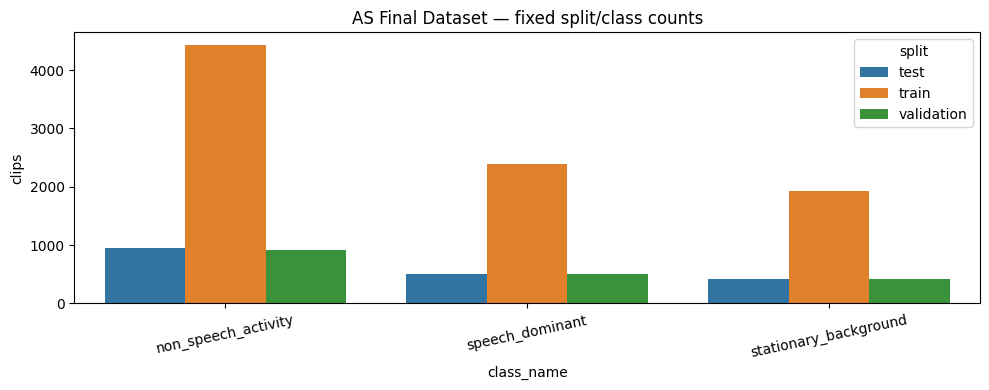

Integrity checks: PASS
- unique IDs: 12466
- unique PCM hashes: 12466
- invalid WAV format: 0
- random re-splitting: disabled


In [ ]:
# 5. Visual class balance audit. Fixed repository splits are preserved.
plot_counts = manifest.groupby(['split', 'class_name']).size().reset_index(name='clips')
plt.figure(figsize=(10, 4))
sns.barplot(data=plot_counts, x='class_name', y='clips', hue='split')
plt.title('AS Final Dataset — fixed split/class counts')
plt.xticks(rotation=12)
plt.tight_layout()
plt.savefig(WORK_DIR / 'dataset_class_balance.png', dpi=160)
plt.show()

print('Integrity checks: PASS')
print('- unique IDs:', manifest['final_id'].nunique())
print('- unique PCM hashes:', manifest['pcm_sha256'].nunique())
print('- invalid WAV format: 0')
print('- random re-splitting: disabled')


## Features and transfer-learning teacher

The deployment student uses 64-bin log-Mel features. Each clip's overall log-energy mean is removed before per-Mel normalization, reducing the risk that the CNN learns the retired LOUD label from absolute amplitude. The DSP path should handle calibrated physical severity.

A frozen YAMNet model supplies 1,024-dimensional AudioSet embeddings. A dataset-specific three-class head is trained only on the training split, then its softened probabilities guide the DS-CNN student. This is stronger than mapping YAMNet keyword names directly to AuraSync classes.


In [ ]:
# 6. Exact preprocessing used by training, INT8 testing and live inference.
MEL_FILTERBANK = librosa.filters.mel(
    sr=SAMPLE_RATE, n_fft=N_FFT, n_mels=N_MELS,
    fmin=FMIN, fmax=FMAX, htk=False, norm='slaney'
).astype(np.float32)
HANN_WINDOW = librosa.filters.get_window('hann', WIN_LENGTH, fftbins=True).astype(np.float32)

def load_audio_16k(path):
    y, _ = librosa.load(path, sr=SAMPLE_RATE, mono=True)
    y = np.asarray(y, dtype=np.float32)
    if not np.all(np.isfinite(y)):
        raise ValueError(f'Non-finite audio: {path}')
    return y

def fix_one_second(y):
    y = np.asarray(y, dtype=np.float32)
    if len(y) < TARGET_SAMPLES:
        y = np.pad(y, (0, TARGET_SAMPLES - len(y)))
    else:
        y = y[:TARGET_SAMPLES]
    y = y - np.mean(y)
    return y.astype(np.float32)

def extract_logmel(y):
    y = fix_one_second(y)
    stft = librosa.stft(
        y, n_fft=N_FFT, hop_length=HOP_LENGTH, win_length=WIN_LENGTH,
        window='hann', center=False, pad_mode='constant'
    )
    power = (np.abs(stft) ** 2).astype(np.float32)
    mel = np.maximum(MEL_FILTERBANK @ power, LOG_EPS)
    logmel = np.log(mel).T.astype(np.float32)
    if logmel.shape[0] < TIME_FRAMES:
        logmel = np.pad(logmel, ((0, TIME_FRAMES - logmel.shape[0]), (0, 0)), mode='edge')
    logmel = logmel[:TIME_FRAMES, :]
    # Per-clip cepstral mean normalization removes absolute level shortcut.
    logmel = logmel - float(logmel.mean())
    if logmel.shape != (TIME_FRAMES, N_MELS):
        raise RuntimeError(f'Unexpected log-Mel shape: {logmel.shape}')
    return logmel.astype(np.float32)

demo_path = DATASET_DIR / manifest.iloc[0]['relative_path']
demo_audio = load_audio_16k(demo_path)
print('Audio shape:', demo_audio.shape)
print('Log-Mel shape:', extract_logmel(demo_audio).shape)


Audio shape: (16000,)
Log-Mel shape: (49, 64)


In [ ]:
# 7. Load the frozen YAMNet feature extractor.
YAMNET_URL = 'https://tfhub.dev/google/yamnet/1'
print('Loading YAMNet:', YAMNET_URL)
yamnet = hub.load(YAMNET_URL)

def extract_yamnet_embedding(y):
    waveform = tf.convert_to_tensor(fix_one_second(y), dtype=tf.float32)
    _scores, embeddings, _spectrogram = yamnet(waveform)
    emb = embeddings.numpy().astype(np.float32)
    # Mean + standard deviation preserves context and temporal variation.
    return np.concatenate([emb.mean(axis=0), emb.std(axis=0)], axis=0).astype(np.float32)

print('YAMNet embedding feature size:', extract_yamnet_embedding(demo_audio).shape)


Loading YAMNet: https://tfhub.dev/google/yamnet/1
YAMNet embedding feature size: (2048,)


In [ ]:
# 8. Extract/cache log-Mel and YAMNet features for each fixed split.
cache_path = CACHE_DIR / f'features_{repo_commit[:12]}_mel{N_MELS}.npz'
meta_cache = CACHE_DIR / f'feature_manifest_{repo_commit[:12]}.csv'

if cache_path.exists() and meta_cache.exists():
    print('Loading cached features:', cache_path)
    cache = np.load(cache_path)
    feature_manifest = pd.read_csv(meta_cache)
else:
    logmel_list, yamnet_list, label_list, split_list, id_list = [], [], [], [], []
    for row in tqdm(manifest.itertuples(index=False), total=len(manifest), desc='Log-Mel + YAMNet'):
        path = DATASET_DIR / row.relative_path
        audio = load_audio_16k(path)
        logmel_list.append(extract_logmel(audio))
        yamnet_list.append(extract_yamnet_embedding(audio))
        label_list.append(int(row.class_id))
        split_list.append(row.split)
        id_list.append(row.final_id)

    cache_dict = {
        'logmel': np.asarray(logmel_list, dtype=np.float32),
        'yamnet': np.asarray(yamnet_list, dtype=np.float32),
        'labels': np.asarray(label_list, dtype=np.int64),
    }
    np.savez(cache_path, **cache_dict)
    feature_manifest = pd.DataFrame({'final_id': id_list, 'split': split_list, 'class_id': label_list})
    feature_manifest.to_csv(meta_cache, index=False)
    cache = np.load(cache_path)

X_logmel_all = cache['logmel']
X_yamnet_all = cache['yamnet']
y_all = cache['labels']

split_indices = {
    split: np.flatnonzero(feature_manifest['split'].to_numpy() == split)
    for split in ['train', 'validation', 'test']
}
train_idx, val_idx, test_idx = split_indices['train'], split_indices['validation'], split_indices['test']
print('Log-Mel:', X_logmel_all.shape, 'YAMNet:', X_yamnet_all.shape)
print('Train/validation/test:', len(train_idx), len(val_idx), len(test_idx))
assert not set(train_idx) & set(val_idx)
assert not set(train_idx) & set(test_idx)
assert not set(val_idx) & set(test_idx)


Log-Mel + YAMNet:   0%|          | 0/12466 [00:00<?, ?it/s]

Log-Mel: (12466, 49, 64) YAMNet: (12466, 2048)
Train/validation/test: 8750 1840 1876


## Train the YAMNet transfer-learning teacher head

YAMNet is frozen. Only the compact three-class head is trained. The untouched validation split controls early stopping; the test split is evaluated once for reporting.


In [ ]:
# 9. Normalize YAMNet embeddings using training statistics only.
teacher_mean = X_yamnet_all[train_idx].mean(axis=0).astype(np.float32)
teacher_std = (X_yamnet_all[train_idx].std(axis=0) + 1e-5).astype(np.float32)

def normalize_teacher(X):
    return ((X - teacher_mean) / teacher_std).astype(np.float32)

X_teacher_train = normalize_teacher(X_yamnet_all[train_idx])
X_teacher_val = normalize_teacher(X_yamnet_all[val_idx])
X_teacher_test = normalize_teacher(X_yamnet_all[test_idx])
y_train_ids, y_val_ids, y_test_ids = y_all[train_idx], y_all[val_idx], y_all[test_idx]

teacher_class_counts = np.bincount(y_train_ids, minlength=CLASS_COUNT)
teacher_class_weights = {
    i: float(len(y_train_ids) / (CLASS_COUNT * teacher_class_counts[i]))
    for i in range(CLASS_COUNT)
}
print('Teacher class weights:', teacher_class_weights)


Teacher class weights: {0: 1.506542699724518, 1: 1.2213847012841987, 2: 0.6589847868654918}


In [ ]:
# 10. Dataset-specific YAMNet teacher head.
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

teacher_input = tf.keras.Input(shape=(X_teacher_train.shape[1],), name='yamnet_mean_std_embedding')
x = tf.keras.layers.LayerNormalization(name='teacher_norm')(teacher_input)
x = tf.keras.layers.Dense(256, activation='relu', name='teacher_dense_256')(x)
x = tf.keras.layers.Dropout(0.30)(x)
x = tf.keras.layers.Dense(96, activation='relu', name='teacher_dense_96')(x)
x = tf.keras.layers.Dropout(0.20)(x)
teacher_logits = tf.keras.layers.Dense(CLASS_COUNT, name='teacher_logits')(x)
teacher_probs_output = tf.keras.layers.Activation('softmax', name='teacher_probs')(teacher_logits)
teacher_head = tf.keras.Model(teacher_input, teacher_probs_output, name='AuraSync_YAMNet_Transfer_Head')
teacher_head.compile(
    optimizer=tf.keras.optimizers.AdamW(learning_rate=8e-4, weight_decay=1e-4),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

teacher_callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=10, mode='max', restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-5),
]
teacher_history = teacher_head.fit(
    X_teacher_train, y_train_ids,
    validation_data=(X_teacher_val, y_val_ids),
    epochs=50, batch_size=128, class_weight=teacher_class_weights,
    callbacks=teacher_callbacks, verbose=1
)
teacher_head.save(EXPORT_DIR / 'yamnet_transfer_teacher_head.keras')


Epoch 1/50
69/69 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.8933 - loss: 0.2647 - val_accuracy: 0.9435 - val_loss: 0.1322 - learning_rate: 8.0000e-04
Epoch 2/50
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9473 - loss: 0.1275 - val_accuracy: 0.9516 - val_loss: 0.1257 - learning_rate: 8.0000e-04
Epoch 3/50
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9591 - loss: 0.0968 - val_accuracy: 0.9473 - val_loss: 0.1320 - learning_rate: 8.0000e-04
Epoch 4/50
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9670 - loss: 0.0776 - val_accuracy: 0.9484 - val_loss: 0.1314 - learning_rate: 8.0000e-04
Epoch 5/50
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9762 - loss: 0.0582 - val_accuracy: 0.9467 - val_loss: 0.1395 - learning_rate: 8.0000e-04
Epoch 6/50
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9816 - loss: 0.0506 - val_accuracy: 0.9511 - val_loss: 0.1434 - learning_rate: 8.0000e-04
Epoch 7/50
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9870 - l

In [ ]:
# 11. Evaluate teacher and create softened targets for distillation.
teacher_val_probs = teacher_head.predict(X_teacher_val, batch_size=256, verbose=0)
teacher_test_probs = teacher_head.predict(X_teacher_test, batch_size=256, verbose=0)
teacher_train_probs = teacher_head.predict(X_teacher_train, batch_size=256, verbose=0)
teacher_test_pred = teacher_test_probs.argmax(axis=1)

teacher_accuracy = accuracy_score(y_test_ids, teacher_test_pred)
teacher_macro_f1 = f1_score(y_test_ids, teacher_test_pred, average='macro')
print('Teacher test accuracy:', round(teacher_accuracy, 4))
print('Teacher test macro-F1:', round(teacher_macro_f1, 4))
print(classification_report(y_test_ids, teacher_test_pred, target_names=LABELS, digits=4))

def soften_probabilities(probabilities, temperature):
    p = np.clip(np.asarray(probabilities, dtype=np.float32), 1e-7, 1.0)
    p = p ** (1.0 / float(temperature))
    return (p / p.sum(axis=1, keepdims=True)).astype(np.float32)

teacher_train_soft = soften_probabilities(teacher_train_probs, DISTILL_TEMPERATURE)
teacher_val_soft = soften_probabilities(teacher_val_probs, DISTILL_TEMPERATURE)


Teacher test accuracy: 0.9606
Teacher test macro-F1: 0.9576
                       precision    recall  f1-score   support

stationary_background     0.9315    0.9181    0.9248       415
      speech_dominant     0.9844    0.9863    0.9854       512
  non_speech_activity     0.9602    0.9652    0.9627       949

             accuracy                         0.9606      1876
            macro avg     0.9587    0.9565    0.9576      1876
         weighted avg     0.9604    0.9606    0.9605      1876



## Normalize and balance student inputs

The student sees all training clips. Minority classes are deterministically oversampled for class-balanced optimization; validation and test sets are never oversampled. SpecAugment, small feature noise, time shift and mixup improve generalization.


In [ ]:
# 12. Student log-Mel normalization from training split only.
X_train_raw = X_logmel_all[train_idx]
X_val_raw = X_logmel_all[val_idx]
X_test_raw = X_logmel_all[test_idx]

mel_mean = X_train_raw.mean(axis=(0, 1)).astype(np.float32)
mel_std = (X_train_raw.std(axis=(0, 1)) + 1e-5).astype(np.float32)

def normalize_logmel(X):
    return (((X - mel_mean[None, None, :]) / mel_std[None, None, :])[..., None]).astype(np.float32)

X_train = normalize_logmel(X_train_raw)
X_val = normalize_logmel(X_val_raw)
X_test = normalize_logmel(X_test_raw)

# Deterministic oversampling to the largest class.
rng = np.random.default_rng(SEED)
per_class_indices = [np.flatnonzero(y_train_ids == i) for i in range(CLASS_COUNT)]
target_per_class = max(len(v) for v in per_class_indices)
balanced_local_indices = np.concatenate([
    rng.choice(indices, size=target_per_class, replace=len(indices) < target_per_class)
    for indices in per_class_indices
])
rng.shuffle(balanced_local_indices)

X_train_bal = X_train[balanced_local_indices]
y_train_bal = y_train_ids[balanced_local_indices]
teacher_train_bal = teacher_train_soft[balanced_local_indices]
y_train_onehot = tf.keras.utils.to_categorical(y_train_bal, CLASS_COUNT).astype(np.float32)
y_val_onehot = tf.keras.utils.to_categorical(y_val_ids, CLASS_COUNT).astype(np.float32)

print('Balanced training examples:', len(X_train_bal))
print(pd.Series(y_train_bal).map(ID_TO_LABEL).value_counts())


Balanced training examples: 13278
speech_dominant          4426
stationary_background    4426
non_speech_activity      4426
Name: count, dtype: int64


In [ ]:
# 13. tf.data augmentation, including SpecAugment and mixup.
AUTOTUNE = tf.data.AUTOTUNE

def spec_augment(x, targets):
    x = tf.cast(x, tf.float32)
    shift = tf.random.uniform([], -3, 4, dtype=tf.int32)
    x = tf.roll(x, shift=shift, axis=0)
    x = x + tf.random.normal(tf.shape(x), stddev=0.025)

    # One time mask.
    width_t = tf.random.uniform([], 0, 7, dtype=tf.int32)
    start_t = tf.random.uniform([], 0, TIME_FRAMES - width_t + 1, dtype=tf.int32)
    time_mask = tf.concat([
        tf.ones([start_t]), tf.zeros([width_t]),
        tf.ones([TIME_FRAMES - start_t - width_t])
    ], axis=0)
    x = x * time_mask[:, None, None]

    # One frequency mask.
    width_f = tf.random.uniform([], 0, 9, dtype=tf.int32)
    start_f = tf.random.uniform([], 0, N_MELS - width_f + 1, dtype=tf.int32)
    freq_mask = tf.concat([
        tf.ones([start_f]), tf.zeros([width_f]),
        tf.ones([N_MELS - start_f - width_f])
    ], axis=0)
    x = x * freq_mask[None, :, None]
    return x, targets

def mixup_batch(x, targets):
    n = tf.shape(x)[0]
    order = tf.random.shuffle(tf.range(n))
    lam = tf.random.uniform([], 0.70, 1.0)
    x = lam * x + (1.0 - lam) * tf.gather(x, order)
    hard = lam * targets['hard_output'] + (1.0 - lam) * tf.gather(targets['hard_output'], order)
    soft = lam * targets['distill_output'] + (1.0 - lam) * tf.gather(targets['distill_output'], order)
    return x, {'hard_output': hard, 'distill_output': soft}

def make_train_dataset(seed):
    targets = {'hard_output': y_train_onehot, 'distill_output': teacher_train_bal}
    ds = tf.data.Dataset.from_tensor_slices((X_train_bal, targets))
    ds = ds.shuffle(len(X_train_bal), seed=seed, reshuffle_each_iteration=True)
    ds = ds.map(spec_augment, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE, drop_remainder=False)
    ds = ds.map(mixup_batch, num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

val_targets = {'hard_output': y_val_onehot, 'distill_output': teacher_val_soft}
val_ds = tf.data.Dataset.from_tensor_slices((X_val, val_targets)).batch(BATCH_SIZE).prefetch(AUTOTUNE)


In [ ]:
# 14. Quantization-friendly accurate DS-CNN student.
def ds_block(x, filters, stride=1, name='ds'):
    x = tf.keras.layers.DepthwiseConv2D(
        3, strides=stride, padding='same', use_bias=False, name=f'{name}_dw'
    )(x)
    x = tf.keras.layers.BatchNormalization(name=f'{name}_dw_bn')(x)
    x = tf.keras.layers.ReLU(max_value=6.0, name=f'{name}_dw_relu')(x)
    x = tf.keras.layers.Conv2D(
        filters, 1, padding='same', use_bias=False, name=f'{name}_pw'
    )(x)
    x = tf.keras.layers.BatchNormalization(name=f'{name}_pw_bn')(x)
    return tf.keras.layers.ReLU(max_value=6.0, name=f'{name}_pw_relu')(x)

def build_student(seed):
    tf.keras.utils.set_random_seed(seed)
    inputs = tf.keras.Input((TIME_FRAMES, N_MELS, 1), name='logmel_input')
    x = tf.keras.layers.Conv2D(32, 3, strides=2, padding='same', use_bias=False, name='stem_conv')(inputs)
    x = tf.keras.layers.BatchNormalization(name='stem_bn')(x)
    x = tf.keras.layers.ReLU(max_value=6.0, name='stem_relu')(x)
    x = ds_block(x, 48, stride=1, name='ds1')
    x = ds_block(x, 64, stride=2, name='ds2')
    x = ds_block(x, 96, stride=2, name='ds3')
    x = ds_block(x, 128, stride=2, name='ds4')
    x = ds_block(x, 128, stride=1, name='ds5')
    x = tf.keras.layers.GlobalAveragePooling2D(name='global_average_pool')(x)
    x = tf.keras.layers.Dropout(0.20, name='student_dropout')(x)
    logits = tf.keras.layers.Dense(CLASS_COUNT, name='student_logits')(x)
    hard_output = tf.keras.layers.Activation('softmax', name='hard_output')(logits)
    scaled_logits = tf.keras.layers.Rescaling(1.0 / DISTILL_TEMPERATURE, name='temperature_scale')(logits)
    distill_output = tf.keras.layers.Activation('softmax', name='distill_output')(scaled_logits)

    train_model = tf.keras.Model(inputs, [hard_output, distill_output], name='AuraSync_DS_CNN_Distillation_Train')
    inference_model = tf.keras.Model(inputs, hard_output, name='AuraSync_DS_CNN_3Class_Inference')
    train_model.compile(
        optimizer=tf.keras.optimizers.AdamW(learning_rate=1.2e-3, weight_decay=1e-4),
        loss={
            'hard_output': tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.03),
            'distill_output': tf.keras.losses.KLDivergence(),
        },
        loss_weights={
            'hard_output': HARD_LOSS_WEIGHT,
            'distill_output': DISTILL_LOSS_WEIGHT,
        },
        metrics={'hard_output': [tf.keras.metrics.CategoricalAccuracy(name='accuracy')]}
    )
    return train_model, inference_model

preview_train_model, preview_inference_model = build_student(SEED)
preview_inference_model.summary()
print('Student parameters:', preview_inference_model.count_params())
del preview_train_model, preview_inference_model
gc.collect()


Model: "AuraSync_DS_CNN_3Class_Inference"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ logmel_input (InputLayer)       │ (None, 49, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ stem_conv (Conv2D)              │ (None, 25, 32, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ stem_bn (BatchNormalization)    │ (None, 25, 32, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ stem_relu (ReLU)                │ (None, 25, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds1_dw (DepthwiseConv2D)        │ (None, 25, 32, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds1_dw_bn (BatchNormalization)  │ (None, 25, 32, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds1_dw_relu (ReLU)              │ (None, 25, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds1_pw (Conv2D)                 │ (None, 25, 32, 48)     │         1,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds1_pw_bn (BatchNormalization)  │ (None, 25, 32, 48)     │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds1_pw_relu (ReLU)              │ (None, 25, 32, 48)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds2_dw (DepthwiseConv2D)        │ (None, 13, 16, 48)     │           432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds2_dw_bn (BatchNormalization)  │ (None, 13, 16, 48)     │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds2_dw_relu (ReLU)              │ (None, 13, 16, 48)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds2_pw (Conv2D)                 │ (None, 13, 16, 64)     │         3,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds2_pw_bn (BatchNormalization)  │ (None, 13, 16, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds2_pw_relu (ReLU)              │ (None, 13, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds3_dw (DepthwiseConv2D)        │ (None, 7, 8, 64)       │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds3_dw_bn (BatchNormalization)  │ (None, 7, 8, 64)       │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds3_dw_relu (ReLU)              │ (None, 7, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds3_pw (Conv2D)                 │ (None, 7, 8, 96)       │         6,144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds3_pw_bn (BatchNormalization)  │ (None, 7, 8, 96)       │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds3_pw_relu (ReLU)              │ (None, 7, 8, 96)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds4_dw (DepthwiseConv2D)        │ (None, 4, 4, 96)       │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds4_dw_bn (BatchNormalization)  │ (None, 4, 4, 96)       │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds4_dw_relu (ReLU)              │ (None, 4, 4, 96)       │             

 Total params: 46,867 (183.07 KB)

 Trainable params: 45,139 (176.32 KB)

 Non-trainable params: 1,728 (6.75 KB)

Student parameters: 46867


5494

In [ ]:
# 15. Train two deterministic candidates and select by validation macro-F1.
candidate_rows = []
history_frames = []
best_path = EXPORT_DIR / 'best_aurasync_student_float.keras'
best_val_f1 = -1.0

for run_number, run_seed in enumerate(STUDENT_SEEDS, 1):
    print(f'\n===== STUDENT CANDIDATE {run_number}/{len(STUDENT_SEEDS)} — seed {run_seed} =====')
    tf.keras.backend.clear_session()
    gc.collect()
    train_model, inference_candidate = build_student(run_seed)
    train_ds = make_train_dataset(run_seed)
    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor='val_hard_output_accuracy', patience=12,
            mode='max', restore_best_weights=True
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.5, patience=5,
            min_lr=1e-5, verbose=1
        ),
    ]
    history = train_model.fit(
        train_ds, validation_data=val_ds, epochs=EPOCHS,
        callbacks=callbacks, verbose=1
    )
    val_probs = inference_candidate.predict(X_val, batch_size=256, verbose=0)
    val_pred = val_probs.argmax(axis=1)
    val_acc = accuracy_score(y_val_ids, val_pred)
    val_f1 = f1_score(y_val_ids, val_pred, average='macro')
    candidate_rows.append({
        'run': run_number, 'seed': run_seed,
        'val_accuracy': val_acc, 'val_macro_f1': val_f1,
        'epochs_ran': len(history.history['loss']),
    })
    h = pd.DataFrame(history.history)
    h['run'] = run_number
    h['seed'] = run_seed
    h['epoch'] = np.arange(1, len(h) + 1)
    history_frames.append(h)
    print('Validation accuracy:', round(val_acc, 4), 'macro-F1:', round(val_f1, 4))
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        inference_candidate.save(best_path)

candidate_results = pd.DataFrame(candidate_rows).sort_values('val_macro_f1', ascending=False)
candidate_results.to_csv(EXPORT_DIR / 'student_candidate_results.csv', index=False)
pd.concat(history_frames, ignore_index=True).to_csv(EXPORT_DIR / 'training_history_all_candidates.csv', index=False)
display(candidate_results)

inference_model = tf.keras.models.load_model(best_path, compile=False)
print('Selected float model:', best_path)



===== STUDENT CANDIDATE 1/2 — seed 20260713 =====
Epoch 1/70
208/208 ━━━━━━━━━━━━━━━━━━━━ 17s 41ms/step - distill_output_loss: 0.4932 - hard_output_accuracy: 0.6897 - hard_output_loss: 0.8430 - loss: 1.0911 - val_distill_output_loss: 1.0767 - val_hard_output_accuracy: 0.2255 - val_hard_output_loss: 1.4990 - val_loss: 2.1273 - learning_rate: 0.0012
Epoch 2/70
208/208 ━━━━━━━━━━━━━━━━━━━━ 7s 31ms/step - distill_output_loss: 0.3802 - hard_output_accuracy: 0.7989 - hard_output_loss: 0.7337 - loss: 0.9068 - val_distill_output_loss: 0.9739 - val_hard_output_accuracy: 0.2848 - val_hard_output_loss: 1.3813 - val_loss: 1.9463 - learning_rate: 0.0012
Epoch 3/70
208/208 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - distill_output_loss: 0.3388 - hard_output_accuracy: 0.8373 - hard_output_loss: 0.6883 - loss: 0.8352 - val_distill_output_loss: 0.4234 - val_hard_output_accuracy: 0.8598 - val_hard_output_loss: 0.4219 - val_loss: 0.7002 - learning_rate: 0.0012
Epoch 4/70
208/208 ━━━━━━━━━━━━━━━━━━━━ 7s 34ms/st

,run,seed,val_accuracy,val_macro_f1,epochs_ran
0,1,20260713,0.932609,0.92888,45
1,2,1729,0.931522,0.92713,67


Selected float model: /content/aurasync_as_final_work/export/best_aurasync_student_float.keras


Float test accuracy: 0.8977
Float balanced accuracy: 0.885
Float macro-F1: 0.889
                       precision    recall  f1-score   support

stationary_background     0.8177    0.7783    0.7975       415
      speech_dominant     0.9704    0.9609    0.9657       512
  non_speech_activity     0.8922    0.9157    0.9038       949

             accuracy                         0.8977      1876
            macro avg     0.8934    0.8850    0.8890      1876
         weighted avg     0.8971    0.8977    0.8972      1876



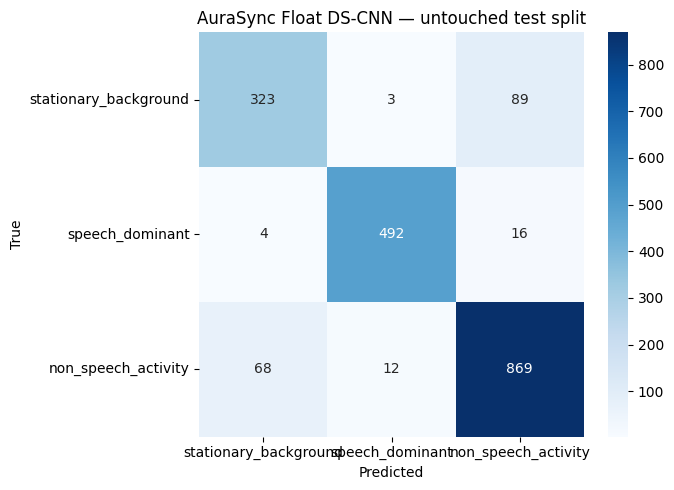

In [ ]:
# 16. Untouched float-model test evaluation.
float_test_probs = inference_model.predict(X_test, batch_size=256, verbose=0)
float_test_pred = float_test_probs.argmax(axis=1)
float_test_accuracy = accuracy_score(y_test_ids, float_test_pred)
float_test_balanced_accuracy = balanced_accuracy_score(y_test_ids, float_test_pred)
float_test_macro_f1 = f1_score(y_test_ids, float_test_pred, average='macro')

print('Float test accuracy:', round(float_test_accuracy, 4))
print('Float balanced accuracy:', round(float_test_balanced_accuracy, 4))
print('Float macro-F1:', round(float_test_macro_f1, 4))
print(classification_report(y_test_ids, float_test_pred, target_names=LABELS, digits=4))

float_cm = confusion_matrix(y_test_ids, float_test_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(float_cm, annot=True, fmt='d', cmap='Blues', xticklabels=LABELS, yticklabels=LABELS)
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('AuraSync Float DS-CNN — untouched test split')
plt.tight_layout()
plt.savefig(EXPORT_DIR / 'float_confusion_matrix.png', dpi=170)
plt.show()


## Full INT8 quantization and parity testing

Representative calibration examples are selected from every class. The quantized model receives and returns INT8 tensors. The entire untouched test split is run through the TFLite interpreter, and the accuracy drop from float is reported.


In [ ]:
# 17. Convert the selected student to full INT8 TFLite.
representative_indices = []
rng = np.random.default_rng(SEED)
for class_id in range(CLASS_COUNT):
    ids = np.flatnonzero(y_train_ids == class_id)
    representative_indices.extend(rng.choice(ids, size=min(250, len(ids)), replace=False).tolist())
representative_indices = np.asarray(representative_indices, dtype=np.int64)
rng.shuffle(representative_indices)

def representative_dataset():
    for i in representative_indices:
        yield [X_train[i:i + 1].astype(np.float32)]

def build_converter(model):
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    converter.representative_dataset = representative_dataset
    converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    converter.inference_input_type = tf.int8
    converter.inference_output_type = tf.int8
    return converter

try:
    int8_bytes = build_converter(inference_model).convert()
except Exception as first_error:
    print('Direct Keras conversion failed; retrying through SavedModel:', first_error)
    saved_model_dir = EXPORT_DIR / 'student_saved_model'
    if saved_model_dir.exists():
        shutil.rmtree(saved_model_dir)
    tf.saved_model.save(inference_model, str(saved_model_dir))
    converter = tf.lite.TFLiteConverter.from_saved_model(str(saved_model_dir))
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    converter.representative_dataset = representative_dataset
    converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    converter.inference_input_type = tf.int8
    converter.inference_output_type = tf.int8
    int8_bytes = converter.convert()

int8_path = EXPORT_DIR / 'aurasync_3class_ds_cnn_full_int8.tflite'
int8_path.write_bytes(int8_bytes)
print('INT8 model:', int8_path)
print('INT8 size:', len(int8_bytes), 'bytes /', round(len(int8_bytes) / 1024, 2), 'KB')


Saved artifact at '/tmp/tmpyxtmp67b'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 49, 64, 1), dtype=tf.float32, name='logmel_input')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  135948198207248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135948198203024: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135948198202256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135948198203216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135948198199760: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135948198204176: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135948198204944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135948198205328: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135948198202640: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135948198206672: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135948198205136:

/usr/local/lib/python3.12/dist-packages/tensorflow/lite/python/convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


INT8 model: /content/aurasync_as_final_work/export/aurasync_3class_ds_cnn_full_int8.tflite
INT8 size: 77384 bytes / 75.57 KB
